# EDA

Section 6. Reads `output/Tetouan_hourly_clean.csv` when the hourly frame is not already in memory.


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
VC_RED = "#D71920"
VC_DARK = "#8B1014"
ZONE_COLORS = ["#D71920", "#4C78A8", "#59A14F"]
zone_cols = ["zone_1_power", "zone_2_power", "zone_3_power"]
weather_cols = [
    "temperature", "humidity", "wind_speed",
    "general_diffuse_flows", "diffuse_flows",
]

if "df_hourly" not in globals():
    df_hourly = (
        pd.read_csv(Path("output") / "Tetouan_hourly_clean.csv", parse_dates=["datetime"])
        .set_index("datetime")
    )


# 6. Exploratory Data Analysis

Focus on:

Trends Over Time
- Seasonality by hour, day and month.
- Difference between weekday and weekend.
- Contribution of each zone.
- The relationship between weather and demand.
- Peak magnitude and peak windows for capacity planning.

Note:
- Peak magnitude is how much peak electricity demand is reached (unit: day)
- Peak window is the peak that appears in any period of time

In [ ]:
df_eda = df_hourly.copy()
df_eda["hour"] = df_eda.index.hour
df_eda["day_of_week"] = df_eda.index.dayofweek
df_eda["day_name"] = df_eda.index.day_name()
df_eda["month"] = df_eda.index.month
df_eda["is_weekend"] = df_eda["day_of_week"].isin([5, 6])

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

display(df_eda[weather_cols + zone_cols + ["total_power"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature,"8,736.00",18.81,5.81,3.60,14.40,18.76,22.87,39.70
humidity,"8,736.00",68.26,15.48,12.71,58.32,69.82,81.35,94.75
wind_speed,"8,736.00",1.96,2.34,0.05,0.08,0.09,4.92,5.93
general_diffuse_flows,"8,736.00",182.70,260.82,0.02,0.06,9.95,326.49,953.35
diffuse_flows,"8,736.00",75.03,119.69,0.04,0.12,8.24,105.88,861.00
zone_1_power,"8,736.00","32,344.97","7,068.92","14,329.11","26,292.95","32,342.30","37,318.00","51,844.26"
zone_2_power,"8,736.00","21,042.51","5,165.18","8,685.95","17,016.90","20,787.23","24,677.61","36,254.70"
zone_3_power,"8,736.00","17,835.41","6,591.01","6,190.64","13,148.47","16,427.66","21,598.45","47,223.77"
total_power,"8,736.00","71,222.89","17,017.67","37,407.60","56,585.36","69,905.00","83,781.63","133,129.83"


### 6.1 Electricity demand evolution over time

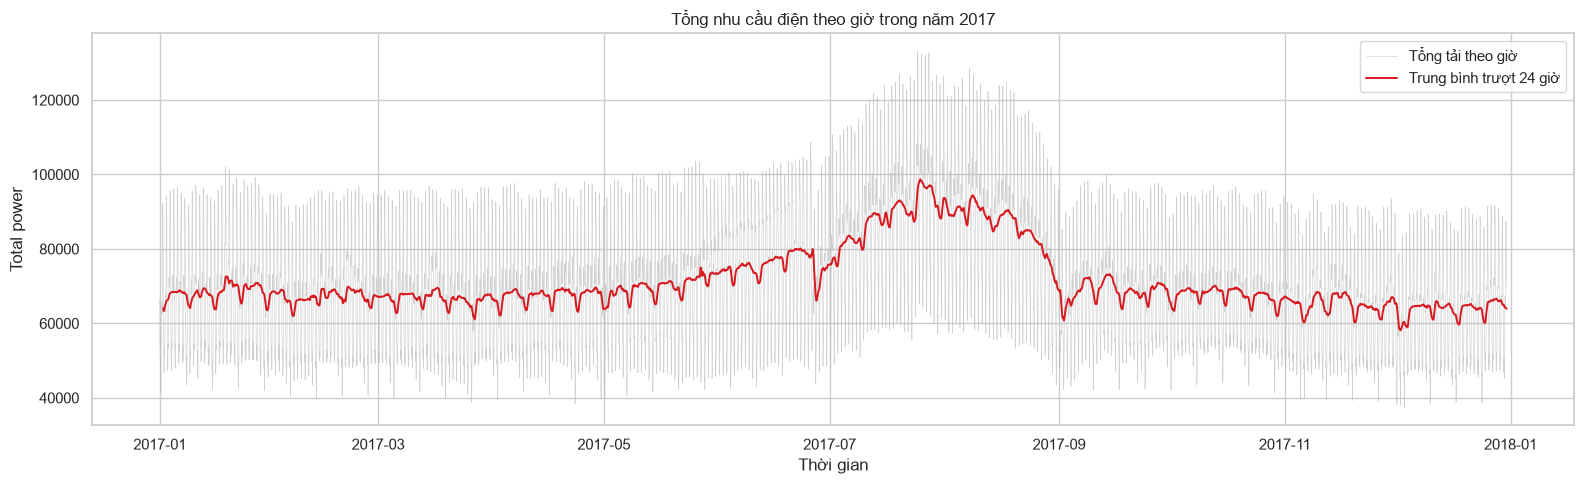

In [ ]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    df_eda.index, df_eda["total_power"],
    color="#B8B8B8", linewidth=0.45, alpha=0.65,
    label="Hourly total load"
)
ax.plot(
    df_eda.index,
    df_eda["total_power"].rolling(24).mean(),
    color=VC_RED, linewidth=1.4,
    label="24-Hour Sliding Average"
)
ax.set_title("Total hourly electricity demand in 2017")
ax.set_xlabel("Time")
ax.set_ylabel("Total power")
ax.legend()
plt.tight_layout()
plt.show()

## 6.2 Seasonality hourly and weekday/weekend

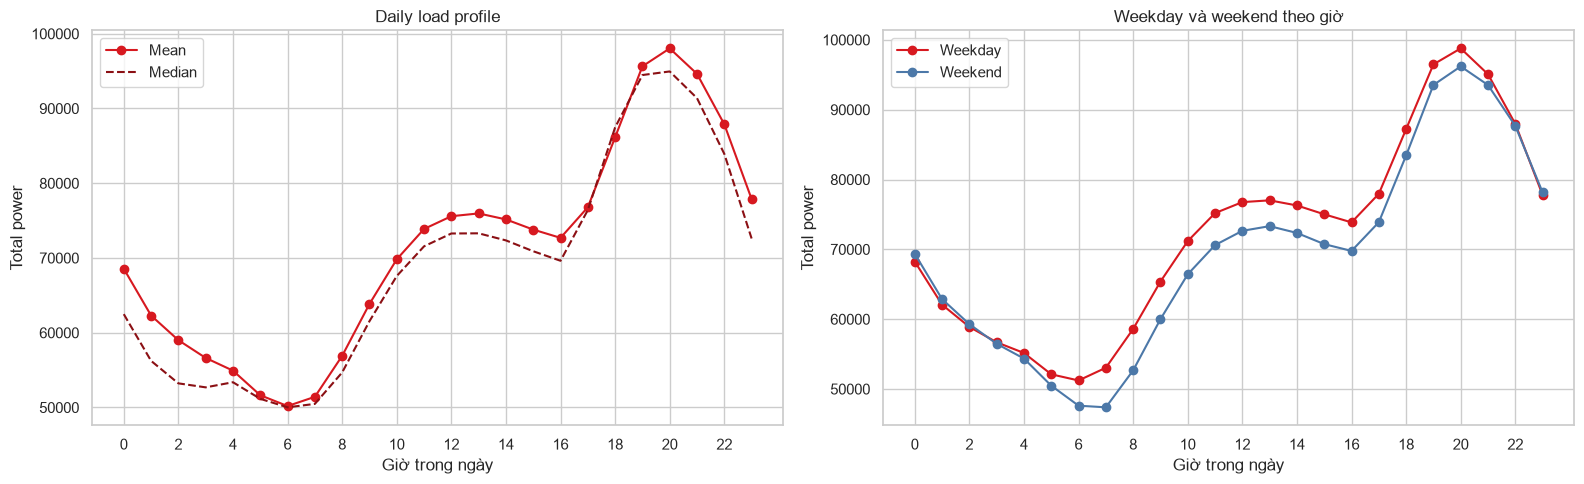

In [ ]:
hourly_profile = df_eda.groupby("hour")["total_power"].agg(["mean", "median"])
weekend_profile = (
    df_eda.groupby(["is_weekend", "hour"])["total_power"]
    .mean().reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(hourly_profile.index, hourly_profile["mean"], marker="o", color=VC_RED, label="Mean")
axes[0].plot(hourly_profile.index, hourly_profile["median"], linestyle="--", color=VC_DARK, label="Median")
axes[0].set_title("Daily load profile")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Total power")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()

for status, label, color in [(False, "Weekday", VC_RED), (True, "Weekend", "#4C78A8")]:
    subset = weekend_profile[weekend_profile["is_weekend"] == status]
    axes[1].plot(subset["hour"], subset["total_power"], marker="o", label=label, color=color)

axes[1].set_title("Weekday and weekend in hours")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Total power")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()

plt.tight_layout()
plt.show()

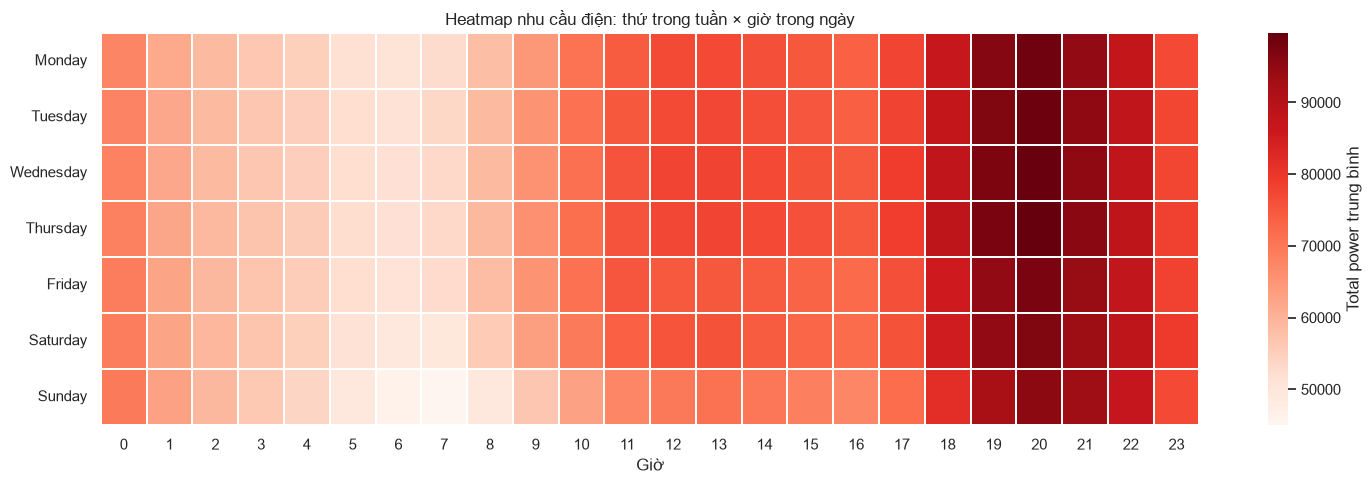

In [ ]:
day_hour_matrix = (
    df_eda.pivot_table(
        index="day_name", columns="hour",
        values="total_power", aggfunc="mean"
    )
    .reindex(day_order)
)

plt.figure(figsize=(15, 5))
sns.heatmap(
    day_hour_matrix, cmap="Reds", linewidths=0.2,
    cbar_kws={"label": "Average total power"}
)
plt.title("Heatmap of electricity demand: weekday × daytime hours")
plt.xlabel("Hour(s)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 6.3 Seasonality and monthly distribution

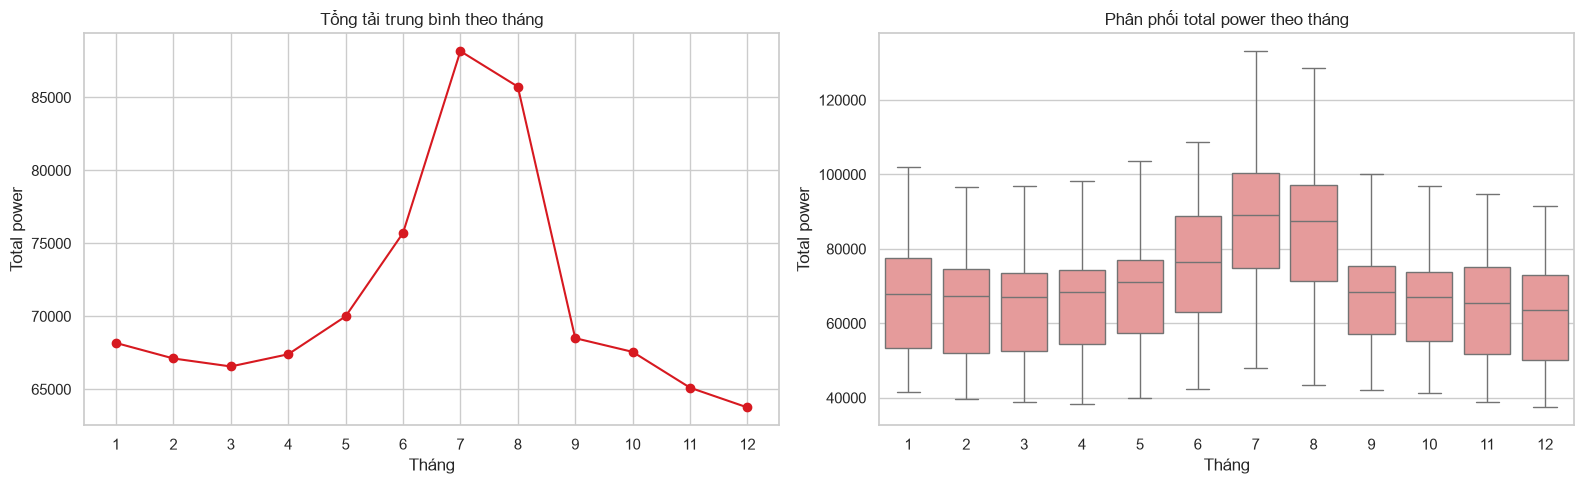

In [ ]:
monthly_profile = df_eda.groupby("month")["total_power"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly_profile.index, monthly_profile.values, marker="o", color=VC_RED)
axes[0].set_title("Average Total Load MoM")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total power")
axes[0].set_xticks(range(1, 13))

sns.boxplot(
    data=df_eda, x="month", y="total_power",
    color="#F28E8E", showfliers=False, ax=axes[1]
)
axes[1].set_title("Monthly total power distribution")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total power")

plt.tight_layout()
plt.show()

### 6.4 Zone-by-zone contributions

,mean_power,share_pct
zone_1_power,"32,344.97",45.41
zone_2_power,"21,042.51",29.54
zone_3_power,"17,835.41",25.04


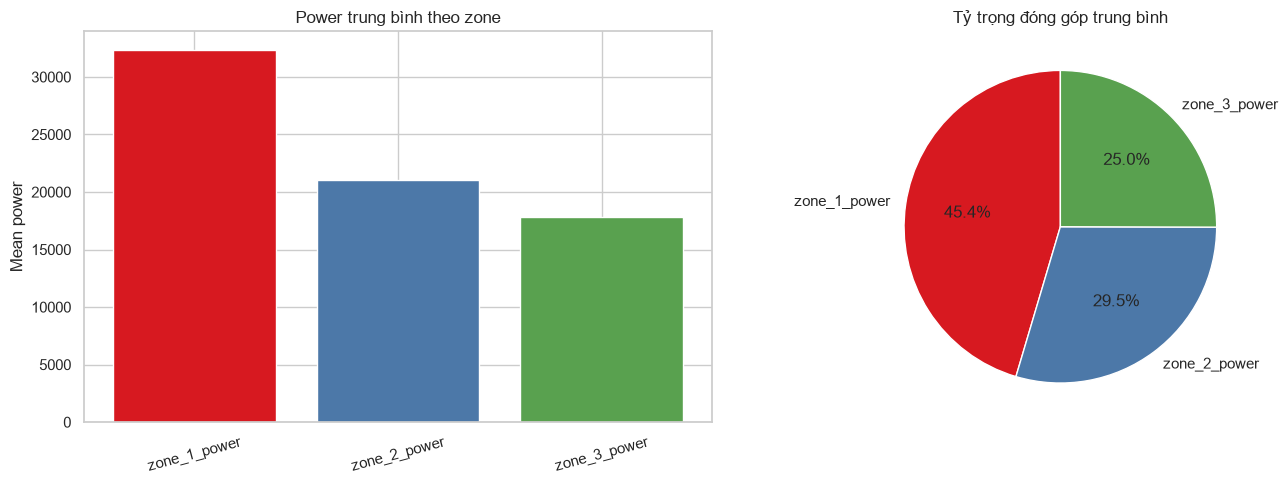

In [ ]:
zone_means = df_eda[zone_cols].mean()
zone_shares = zone_means / zone_means.sum() * 100

zone_summary = pd.DataFrame({
    "mean_power": zone_means,
    "share_pct": zone_shares
})
display(zone_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(zone_means.index, zone_means.values, color=ZONE_COLORS)
axes[0].set_title("Average power by zone")
axes[0].set_ylabel("Mean power")
axes[0].tick_params(axis="x", rotation=15)

axes[1].pie(
    zone_shares.values,
    labels=zone_shares.index,
    autopct="%1.1f%%",
    colors=ZONE_COLORS,
    startangle=90
)
axes[1].set_title("Average contribution ratio")

plt.tight_layout()
plt.show()

### 6.5 The relationship between weather and demand

Correlation reflects only linear relations and does not prove causality. Density charts help to view the nonlinear relationship and the focused observation area.

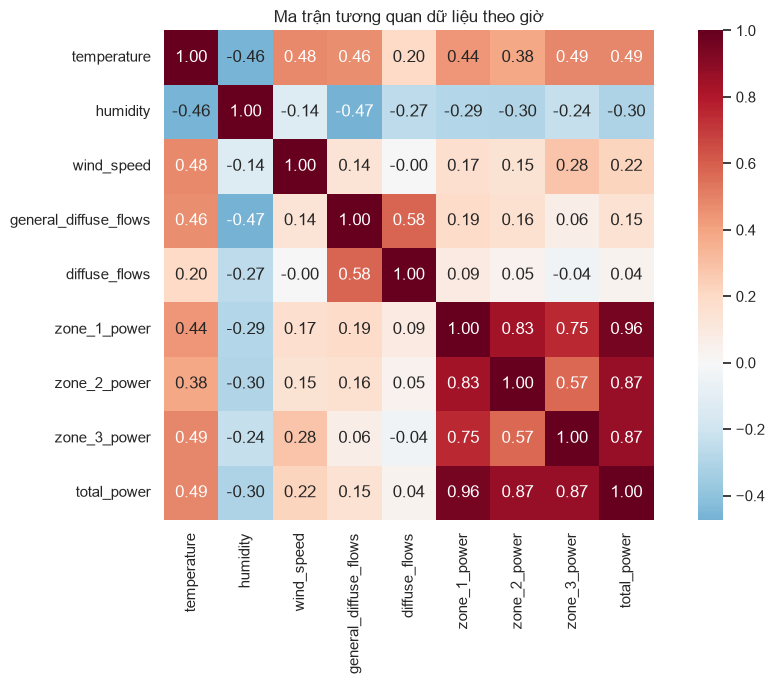

,correlation_with_total_power
zone_1_power,0.96
zone_3_power,0.87
zone_2_power,0.87
temperature,0.49
wind_speed,0.22
general_diffuse_flows,0.15
diffuse_flows,0.04
humidity,-0.30


In [ ]:
corr_cols = weather_cols + zone_cols + ["total_power"]
correlation = df_eda[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, square=True
)
plt.title("Hourly Data Correlation Matrix")
plt.tight_layout()
plt.show()

display(
    correlation["total_power"]
    .drop("total_power")
    .sort_values(ascending=False)
    .to_frame("correlation_with_total_power")
)

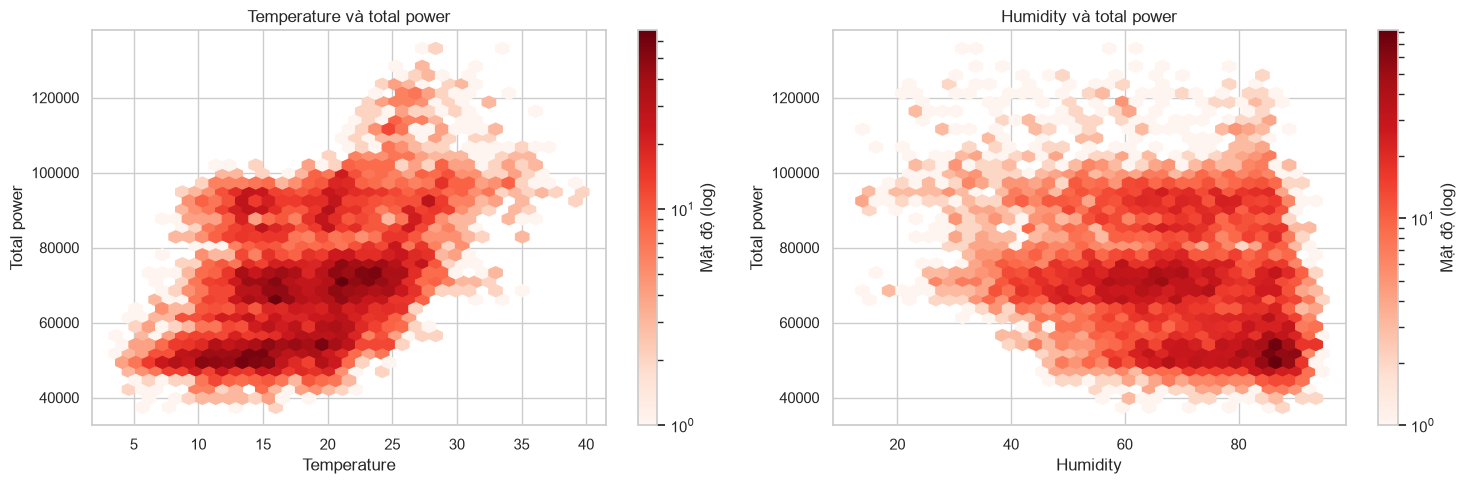

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

hb1 = axes[0].hexbin(
    df_eda["temperature"], df_eda["total_power"],
    gridsize=35, mincnt=1, bins="log", cmap="Reds"
)
axes[0].set_title("Temperature and total power")
axes[0].set_xlabel("Temperature")
axes[0].set_ylabel("Total power")
fig.colorbar(hb1, ax=axes[0], label="Density (log)")

hb2 = axes[1].hexbin(
    df_eda["humidity"], df_eda["total_power"],
    gridsize=35, mincnt=1, bins="log", cmap="Reds"
)
axes[1].set_title("Humidity and total power")
axes[1].set_xlabel("Humidity")
axes[1].set_ylabel("Total power")
fig.colorbar(hb2, ax=axes[1], label="Density (log)")

plt.tight_layout()
plt.show()

### 6.6 Peak-demand analysis

P90/P95/P99 in this section serves EDA only. When evaluating capacity planning on a test set, the threshold must be calculated from training data to avoid looking ahead.

,total_power_threshold
P90,"94,770.21"
P95,"99,400.44"
P99,"117,373.73"


,total_power,zone_1_power,zone_2_power,zone_3_power,temperature,humidity,hour,month,day_name
datetime,,,,,,,,,
2017-07-24 20:00:00,"133,129.83","51,138.34","34,767.72","47,223.77",28.77,32.91,20,7,Monday
2017-07-27 20:00:00,"132,694.06","50,973.55","34,620.25","47,100.25",27.84,61.21,20,7,Thursday
2017-07-25 20:00:00,"132,330.26","50,886.38","34,489.24","46,954.64",26.87,57.94,20,7,Tuesday
2017-07-26 20:00:00,"132,071.19","50,546.18","34,388.61","47,136.40",33.32,30.69,20,7,Wednesday
2017-07-24 21:00:00,"129,515.26","49,812.62","33,874.68","45,827.95",27.50,33.92,21,7,Monday
2017-08-07 20:00:00,"128,468.68","51,844.26","35,937.28","40,687.15",27.33,78.32,20,8,Monday
2017-07-27 21:00:00,"128,002.79","49,683.99","33,116.46","45,202.34",27.21,62.09,21,7,Thursday
2017-07-25 21:00:00,"127,965.61","49,523.46","32,962.66","45,479.50",25.58,66.15,21,7,Tuesday
2017-07-26 21:00:00,"127,562.67","49,365.05","33,215.19","44,982.43",30.97,39.10,21,7,Wednesday


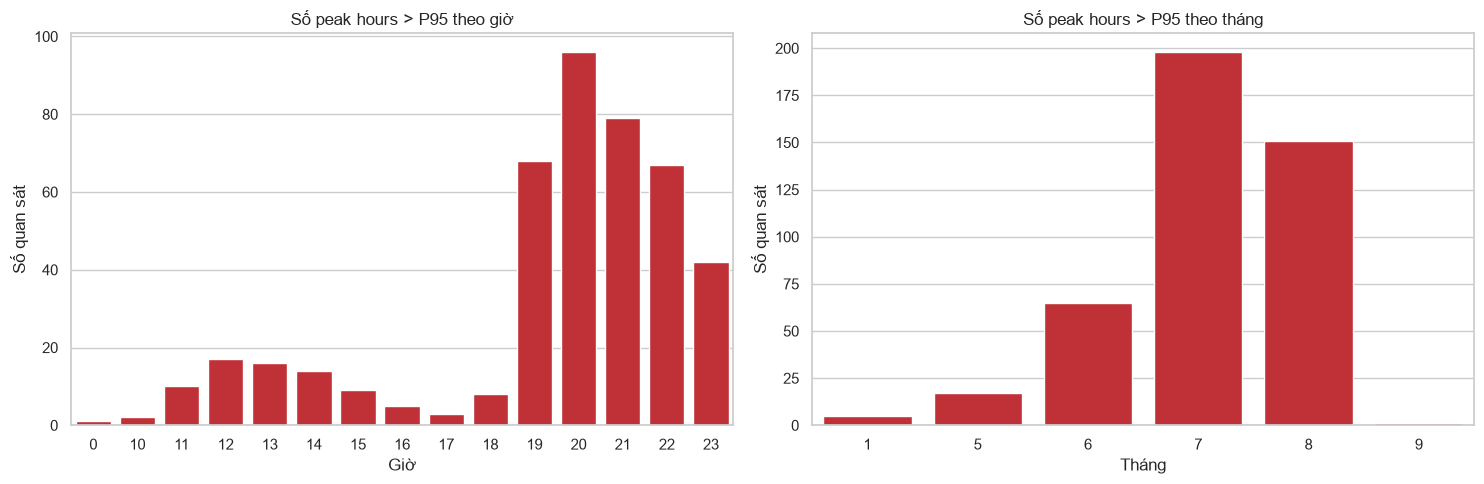

In [ ]:
peak_thresholds = df_eda["total_power"].quantile([0.90, 0.95, 0.99])
peak_thresholds.index = ["P90", "P95", "P99"]
display(peak_thresholds.to_frame("total_power_threshold"))

top_peaks = df_eda.nlargest(20, "total_power")[
    ["total_power"] + zone_cols + ["temperature", "humidity"]
].copy()
top_peaks["hour"] = top_peaks.index.hour
top_peaks["month"] = top_peaks.index.month
top_peaks["day_name"] = top_peaks.index.day_name()
display(top_peaks)

p95_threshold = peak_thresholds.loc["P95"]
peak_hours = df_eda[df_eda["total_power"] > p95_threshold].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=peak_hours, x="hour", color=VC_RED, ax=axes[0])
axes[0].set_title("Number of peak hours > P95 in hours")
axes[0].set_xlabel("Hour(s)")
axes[0].set_ylabel("Number of observations")

sns.countplot(data=peak_hours, x="month", color=VC_RED, ax=axes[1])
axes[1].set_title("Number of peak hours > P95 by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

,overall_share_pct,p95_peak_share_pct,difference_pct_point
zone_1_power,45.41,41.31,-4.10
zone_2_power,29.54,27.46,-2.09
zone_3_power,25.04,31.23,6.19


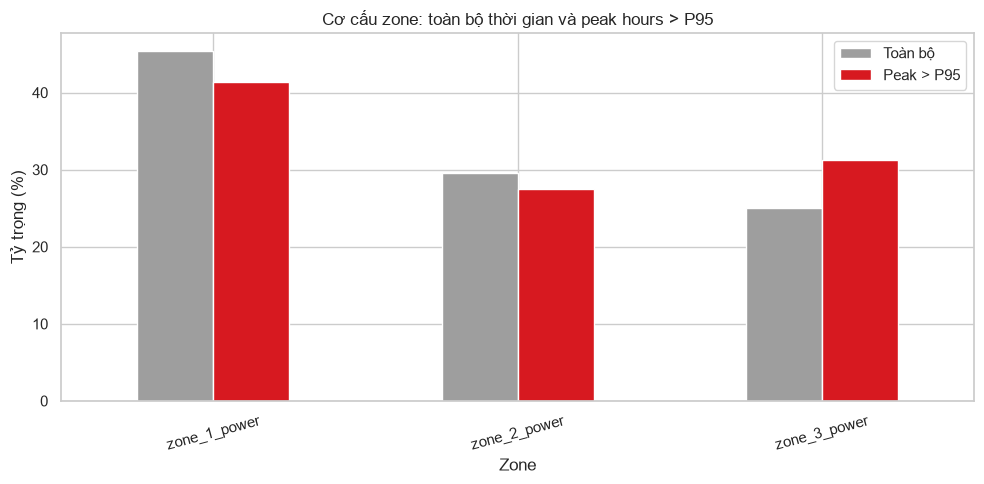

In [ ]:
overall_zone_share = df_eda[zone_cols].mean()
overall_zone_share = overall_zone_share / overall_zone_share.sum() * 100

peak_zone_share = peak_hours[zone_cols].mean()
peak_zone_share = peak_zone_share / peak_zone_share.sum() * 100

zone_share_comparison = pd.DataFrame({
    "overall_share_pct": overall_zone_share,
    "p95_peak_share_pct": peak_zone_share,
    "difference_pct_point": peak_zone_share - overall_zone_share,
})

display(zone_share_comparison)

zone_share_comparison[["overall_share_pct", "p95_peak_share_pct"]].plot(
    kind="bar", figsize=(10, 5), color=["#9E9E9E", VC_RED]
)
plt.title("Zone structure: all time and peak hours > P95")
plt.xlabel("Zone")
plt.ylabel("Proportion (%)")
plt.xticks(rotation=15)
plt.legend(["Full cover", "Peak > P95"])
plt.tight_layout()
plt.show()